# Lezione 4 — Il corpo nero

Modulo *Radiazione termica e segnatura IR* (Master OQI, prof. R. Li Voti).

Dalla conduzione si passa all'irraggiamento. Un corpo nero assorbe tutto
ciò che lo colpisce e, all'equilibrio, emette uno spettro universale: la
legge di Planck. La fisica classica, con l'equipartizione, produce invece
la formula di Rayleigh–Jeans e la catastrofe ultravioletta. Planck la
evita quantizzando l'energia degli oscillatori, \(E=n h f\).

In questa lezione la grandezza disegnata è l'**emittanza spettrale**
emisferica (W/m² per metro di lunghezza d'onda),

\[
M_\lambda(T)=\frac{2\pi h c^2}{\lambda^5}\frac{1}{e^{hc/\lambda k_B T}-1},
\]

che è la formula scritta sulle slide (\(I_\lambda\), in W/m³).


## 0. Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8.4, 4.7),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.unicode_minus": False,
})
np.set_printoptions(precision=4, suppress=True)
print("Ambiente pronto.")

from scipy import constants
from scipy.integrate import quad

H = constants.h
C = constants.c
K_B = constants.k
SIGMA = constants.sigma


Ambiente pronto.


## 1. Planck, Wien, Rayleigh–Jeans

Tre espressioni, un solo spettro.

- Planck, sempre valida: la formula sopra.
- Wien, coda di corta lunghezza d'onda (\(hc/\lambda kT \gg 1\)):
  si trascura il \(-1\) nel denominatore.
- Rayleigh–Jeans, coda di grande lunghezza d'onda (\(hc/\lambda kT \ll 1\)):
  \(M_\lambda \approx 2\pi c k_B T/\lambda^4\).

La Rayleigh–Jeans cresce senza limite al diminuire di \(\lambda\). Integrata
su tutte le frequenze diverge: è la catastrofe ultravioletta. I dati, e la
formula di Planck, hanno un massimo e poi crollano.


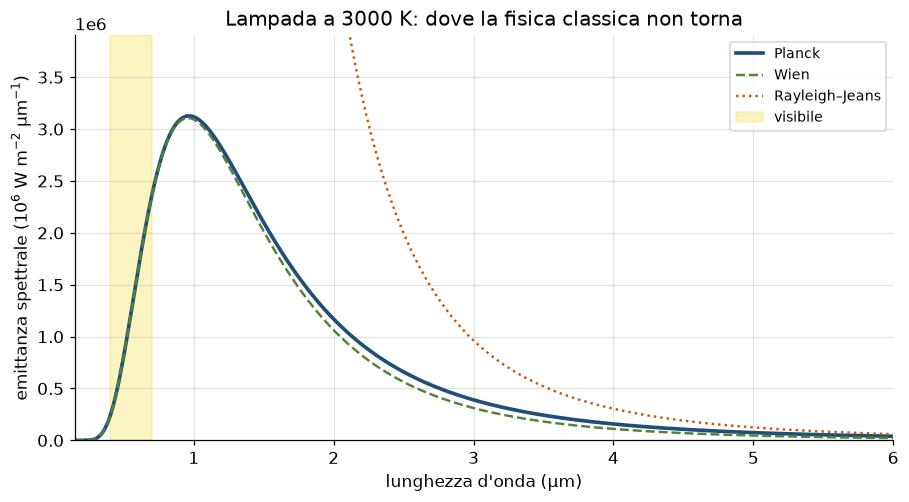

A 0,5 μm e 3000 K, Rayleigh–Jeans / Planck = 1526.7


In [2]:
def planck(lam, T):
    """Emittanza spettrale emisferica, W/m² per metro di λ."""
    lam = np.asarray(lam, dtype=float)
    x = H * C / (lam * K_B * T)
    out = np.zeros_like(x)
    ok = (x > 0) & (x < 700)
    out[ok] = 2 * np.pi * H * C**2 / lam[ok]**5 / np.expm1(x[ok])
    return out

def rayleigh_jeans(lam, T):
    return 2 * np.pi * C * K_B * T / np.asarray(lam, dtype=float)**4

def wien_approx(lam, T):
    lam = np.asarray(lam, dtype=float)
    x = H * C / (lam * K_B * T)
    out = np.zeros_like(x)
    ok = x < 700
    out[ok] = 2 * np.pi * H * C**2 / lam[ok]**5 * np.exp(-x[ok])
    return out

T = 3000.0   # lampada a incandescenza, l'esempio della lezione
lam = np.geomspace(0.15e-6, 8e-6, 1200)
M = planck(lam, T)
Rj = rayleigh_jeans(lam, T)
W = wien_approx(lam, T)

fig, ax = plt.subplots()
ax.plot(lam * 1e6, M / 1e6, color="#1f4e79", lw=2.4, label="Planck")
ax.plot(lam * 1e6, W / 1e6, color="#548235", lw=1.6, ls="--", label="Wien")
ax.plot(lam * 1e6, np.clip(Rj, 0, None) / 1e6, color="#c45911", lw=1.6, ls=":", label="Rayleigh–Jeans")
ax.set_xlim(0.15, 6)
ax.set_ylim(0, np.max(M / 1e6) * 1.25)
ax.axvspan(0.4, 0.7, color="#f4e04d", alpha=0.35, label="visibile")
ax.set_xlabel("lunghezza d'onda (μm)")
ax.set_ylabel(r"emittanza spettrale ($10^6$ W m$^{-2}$ μm$^{-1}$)")
ax.set_title("Lampada a 3000 K: dove la fisica classica non torna")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

# Nel visibile Rayleigh–Jeans sta già molto sopra Planck.
lam_v = 0.5e-6
print(f"A 0,5 μm e 3000 K, Rayleigh–Jeans / Planck = {rayleigh_jeans(lam_v, T)/planck(lam_v, T):.1f}")


## 2. La catastrofe, vista sull'integrale

L'energia totale è l'area sotto la curva. Per Planck l'area da \(\lambda\) fino
all'infinito satura: quasi tutto è già contato arrivati al vicino ultravioletto.
Per Rayleigh–Jeans l'area continua a crescere andando verso \(\lambda\to 0\).


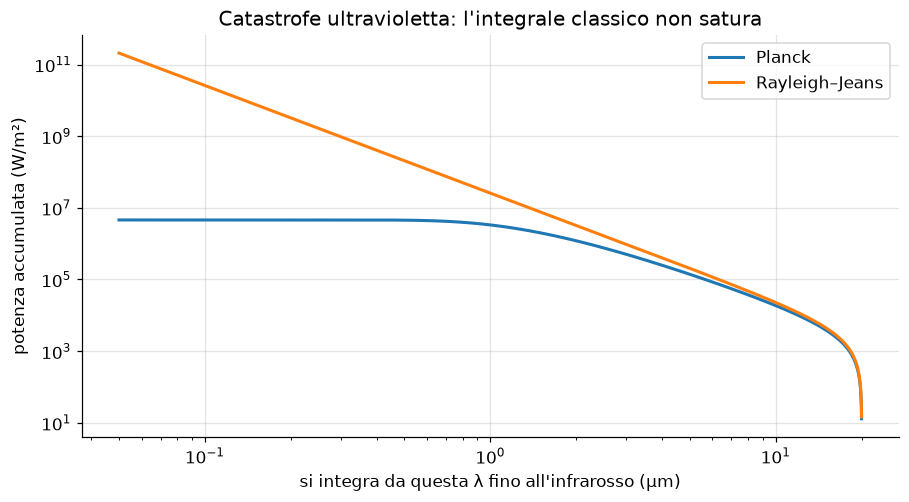

Planck, integrale sulla griglia: 4590044 W/m²
σT⁴ = 4593003 W/m²


In [3]:
def cumulativa_dal_rosso(lam, spettro):
    """Potenza integrata da λ all'estremo rosso della griglia, per ogni λ."""
    # spettro è ordinato con lam crescente: si integra da destra.
    integrale = np.cumsum((spettro * np.gradient(lam))[::-1])[::-1]
    return integrale

T = 3000.0
lam = np.geomspace(0.05e-6, 20e-6, 4000)
cum_P = cumulativa_dal_rosso(lam, planck(lam, T))
cum_R = cumulativa_dal_rosso(lam, rayleigh_jeans(lam, T))

fig, ax = plt.subplots()
ax.loglog(lam * 1e6, cum_P, lw=2, label="Planck")
ax.loglog(lam * 1e6, cum_R, lw=2, label="Rayleigh–Jeans")
ax.set_xlabel("si integra da questa λ fino all'infrarosso (μm)")
ax.set_ylabel(r"potenza accumulata (W/m²)")
ax.set_title("Catastrofe ultravioletta: l'integrale classico non satura")
ax.legend()
fig.tight_layout()
plt.show()

print(f"Planck, integrale sulla griglia: {cum_P[0]:.0f} W/m²")
print(f"σT⁴ = {SIGMA * T**4:.0f} W/m²")
assert np.isclose(cum_P[0], SIGMA * T**4, rtol=0.01)


## 3. Legge di Wien e legge di Stefan–Boltzmann

Il massimo di \(M_\lambda\) sta dove \(x=hc/(\lambda k_B T)\) risolve
\((5-x)e^{x}=5\). La radice è \(x=4{,}9651\), e quindi

\[
\lambda_\mathrm{max}\,T = 2898\,\mu\mathrm{m\cdot K}.
\]

È la legge di spostamento di Wien del 1893, nel valore usato a lezione.
All'aumentare di \(T\) il picco si sposta verso il blu e l'area cresce come \(T^4\):

\[
M=\int_0^\infty M_\lambda\,d\lambda=\sigma T^4,
\qquad
\sigma=\frac{2\pi^5 k_B^4}{15 c^2 h^3}=5{,}67\times 10^{-8}\,\mathrm{W\,m^{-2}\,K^{-4}}.
\]


radice di Wien x = 4.9651
λ_max T = 2897.8 μm·K

sorgente                    λ_max
corpo umano, 37 °C         9.35 μm
lampada                    0.97 μm
Sole                       0.50 μm
stella calda               0.10 μm


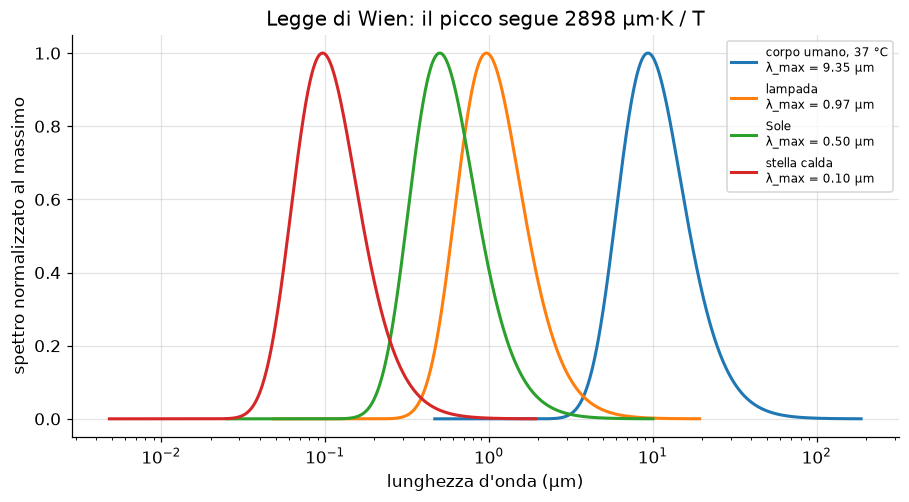

In [4]:
from scipy.optimize import brentq

def g(x):
    return (5 - x) * np.exp(x) - 5

x_max = brentq(g, 1.0, 4.99)
b_wien = H * C / (K_B * x_max)          # m·K
print(f"radice di Wien x = {x_max:.4f}")
print(f"λ_max T = {b_wien*1e6:.1f} μm·K")
assert np.isclose(x_max, 4.9651, atol=1e-3)

casi = [
    ("corpo umano, 37 °C", 310.0),
    ("lampada", 3000.0),
    ("Sole", 5780.0),
    ("stella calda", 30000.0),
]
print(f"\n{'sorgente':22} {'λ_max':>10}")
for nome, T in casi:
    print(f"{nome:22} {b_wien/T*1e6:8.2f} μm")

# Spettri sulla stessa figura, ciascuno normalizzato al proprio massimo:
# si vede lo spostamento, non il fattore enorme fra 310 K e 30 000 K.
fig, ax = plt.subplots()
for nome, T in casi:
    lam = np.geomspace(b_wien / T / 20, b_wien / T * 20, 800)
    M = planck(lam, T)
    ax.plot(lam * 1e6, M / M.max(), lw=2, label=f"{nome}\nλ_max = {b_wien/T*1e6:.2f} μm")
ax.set_xscale("log")
ax.set_xlabel("lunghezza d'onda (μm)")
ax.set_ylabel("spettro normalizzato al massimo")
ax.set_title("Legge di Wien: il picco segue 2898 μm·K / T")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


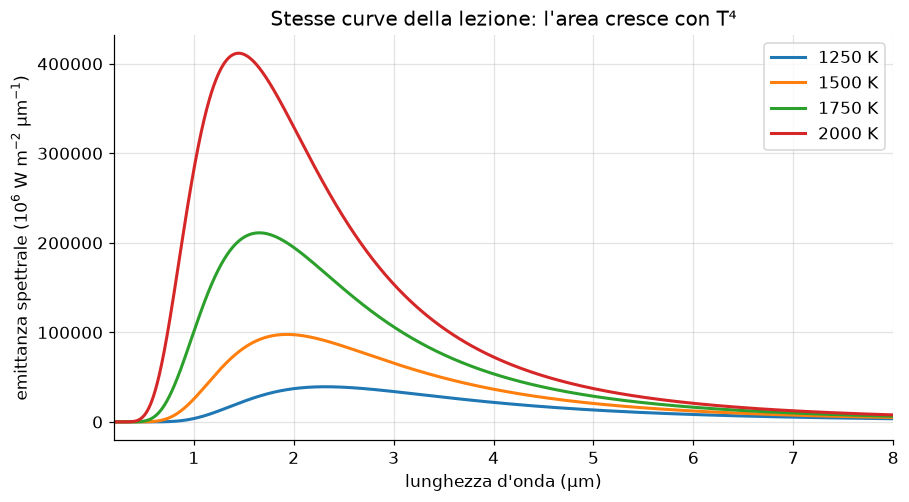

   T (K)    integrale          σT⁴
    1250    1.374e+05    1.384e+05
    1500    2.857e+05    2.871e+05
    1750    5.302e+05    5.318e+05
    2000    9.054e+05    9.073e+05

σ dalla formula = 5.670374e-08
σ di scipy      = 5.670374e-08


In [5]:
# Area sotto le curve a quattro temperature: cresce come T^4.
temperature = np.array([1250.0, 1500.0, 1750.0, 2000.0])
lam = np.geomspace(0.2e-6, 20e-6, 1500)

fig, ax = plt.subplots()
aree = []
for T in temperature:
    M = planck(lam, T)
    ax.plot(lam * 1e6, M / 1e6, lw=2, label=f"{T:.0f} K")
    aree.append(np.trapezoid(M, lam))
ax.set_xlim(0.2, 8)
ax.set_xlabel("lunghezza d'onda (μm)")
ax.set_ylabel(r"emittanza spettrale ($10^6$ W m$^{-2}$ μm$^{-1}$)")
ax.set_title("Stesse curve della lezione: l'area cresce con T⁴")
ax.legend()
fig.tight_layout()
plt.show()

aree = np.array(aree)
previsto = SIGMA * temperature**4
print(f"{'T (K)':>8} {'integrale':>12} {'σT⁴':>12}")
for T, a, p in zip(temperature, aree, previsto):
    print(f"{T:8.0f} {a:12.3e} {p:12.3e}")
assert np.allclose(aree, previsto, rtol=0.01)

# σ ricostruita dalle costanti: 2 π^5 k^4 / (15 c² h³).
sigma_formula = 2 * np.pi**5 * K_B**4 / (15 * C**2 * H**3)
print(f"\nσ dalla formula = {sigma_formula:.6e}")
print(f"σ di scipy      = {SIGMA:.6e}")
assert np.isclose(sigma_formula, SIGMA, rtol=1e-10)


## 4. Corpo grigio e corpo selettivo

Un corpo reale emette una frazione dello spettro di corpo nero.
Se la frazione non dipende da \(\lambda\) è un **corpo grigio**, \(M=\varepsilon\sigma T^4\),
con \(0\le\varepsilon\le 1\). Se dipende da \(\lambda\) è un **corpo selettivo**,

\[
P = A\int_0^\infty \varepsilon_\lambda\, M_\lambda(T)\,d\lambda.
\]

Per un corpo opaco la legge di Kirchhoff dice \(\varepsilon_\lambda=\alpha_\lambda\):
assorbe bene dove emette bene, e \(\varepsilon_\lambda=1-\rho_\lambda\).
Le tre leggi di Kirchhoff ricordate a lezione (spettro continuo del solido
incandescente, righe di emissione del gas rarefatto, righe di assorbimento
del gas freddo davanti a un continuo) sono lo stesso principio letto su
sorgenti diverse. Lo spettro stellare è l'applicazione storica: un continuo
di corpo nero scavato dalle righe dell'atmosfera della stella.


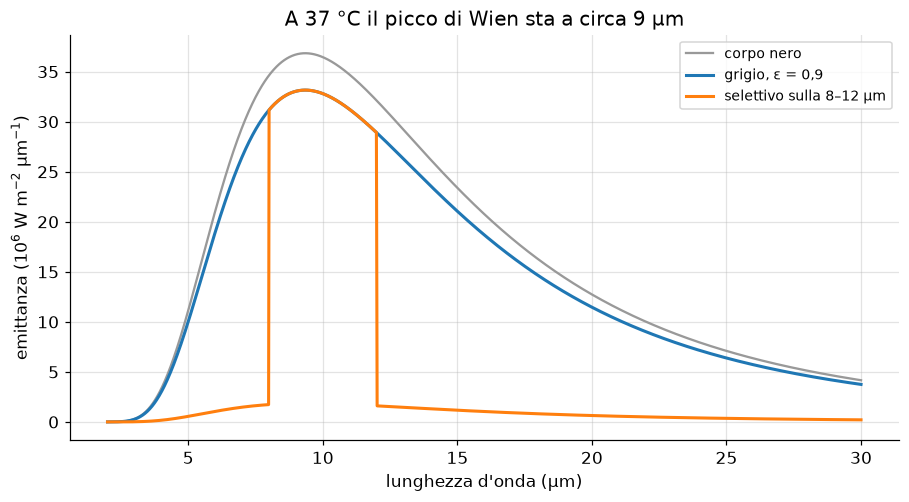

Corpo nero       523.7 W/m²
Grigio ε=0,9     471.3 W/m²
Selettivo        144.3 W/m²
λ_max (37 °C)  9.35 μm


In [6]:
T = 310.0    # pelle, circa 37 °C
lam = np.geomspace(2e-6, 30e-6, 1200)
M = planck(lam, T)

# Selettivo didattico: emette solo nella finestra LWIR 8–12 μm, dove guardano
# molte termocamere. È l'idea, non lo spettro di un materiale vero.
eps_sel = np.where((lam >= 8e-6) & (lam <= 12e-6), 0.9, 0.05)
eps_grey = 0.9

fig, ax = plt.subplots()
ax.plot(lam * 1e6, M / 1e6, color="0.6", lw=1.5, label="corpo nero")
ax.plot(lam * 1e6, eps_grey * M / 1e6, lw=2, label="grigio, ε = 0,9")
ax.plot(lam * 1e6, eps_sel * M / 1e6, lw=2, label="selettivo sulla 8–12 μm")
ax.set_xlabel("lunghezza d'onda (μm)")
ax.set_ylabel(r"emittanza ($10^6$ W m$^{-2}$ μm$^{-1}$)")
ax.set_title("A 37 °C il picco di Wien sta a circa 9 μm")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

P_nero = SIGMA * T**4
P_grey = eps_grey * P_nero
P_sel = np.trapezoid(eps_sel * M, lam)
print(f"Corpo nero     {P_nero:7.1f} W/m²")
print(f"Grigio ε=0,9   {P_grey:7.1f} W/m²")
print(f"Selettivo      {P_sel:7.1f} W/m²")
print(f"λ_max (37 °C)  {b_wien/T*1e6:.2f} μm")


## In sintesi

- Lo spettro di corpo nero è la funzione di Planck. Rayleigh–Jeans è il suo limite di grande \(\lambda\) e diverge nell'ultravioletto.
- Il massimo sta a \(\lambda_\mathrm{max}T=2898\,\mu\mathrm{m\cdot K}\): 9 μm per la pelle, 1 μm per una lampada, 0,5 μm per il Sole.
- L'area è \(\sigma T^4\). Passare da 1250 K a 2000 K non alza la curva di un fattore due: la alza di \((2000/1250)^4\approx 6{,}6\).
- Grigio: un solo numero \(\varepsilon\). Selettivo: \(\varepsilon_\lambda\), e per un opaco \(\varepsilon_\lambda=1-\rho_\lambda\).
